# Step 4 – Predictive and prescriptive analytics: four algorithms + break-even
**Urban home-farming start-up (India) · synthetic data**

Steps 1–3 described the market and diagnosed why customers buy. This notebook answers the professor's remaining
questions: **who will buy (classification), which segments to target (clustering), which features to launch first
(association rules), how much they will pay (regression), and when the business breaks even (prescriptive).**

| Algorithm | Business question | Target / output |
|---|---|---|
| Classification | Will this person buy? Which pilot lead will convert? | `would_buy`, `purchased` |
| Clustering | Which customer segments exist, and which have high / medium / low conversion probability? | segment labels |
| Association rule mining | If customers want features A and B, do they also want C? Which features launch first? | rules (support, confidence, lift) |
| Regression | How much is a customer willing to pay? | `wtp_system` (₹) |
| Prescriptive model | When does the business break even under each strategy? | break-even month, payback month |

The calculations live in `models.py`, so the Streamlit dashboard shows exactly the same results.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt, numpy as np, pandas as pd
from IPython.display import display, Markdown, Image
import analytics as A, models as M, charts as C
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
s, p = A.load()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": C.AXIS, "axes.titleweight": "bold", "axes.titlesize": 11.5})
FIG = 28
def save(fig, name):
    global FIG; FIG += 1
    path = f"figures/{FIG:02d}_{name}.png"; fig.tight_layout(); fig.savefig(path, dpi=150, bbox_inches="tight"); plt.close(fig)
    display(Image(path, width=760))

## 0. Which columns feed which algorithm
Not every column goes into every algorithm. Inputs are what we would know about a customer *before* the outcome;
outcomes are only used as targets or to profile results afterwards.

In [2]:
M.COLUMN_MAP

,Algorithm,Columns used,Why these columns
0,Classification (who will buy),"Target: would_buy (Q15 top-2-box). Inputs: income, income_disclosed, household_size, children, space_level, sun_leve...",Profile + attitude + the price they saw. Max-price and subscription answers are left out: a new lead has not given t...
1,"Classification (lead scoring, pilot)","Target: purchased. Inputs: channel, hours_to_first_contact, price_offered, space_level, income_level, household_size...",Everything the sales team knows about a lead before the close.
2,Clustering (segments),"att_health/eco/tech/time_poor/hobby, space_level, sun_level, income, veg_spend, household_size, children, experience...","Who they are and how they live - not the outcome. Outcomes (would_buy, max price) are used afterwards to profile and..."
3,Association rules (feature bundles),"f_* (9 features wanted, Q12) and g_* (5 crops, Q13) as 0/1 baskets",Tick-box answers are baskets: 'people who want A and B also want C' decides which features launch together.
4,Regression (willingness to pay),"Target: wtp_system (Q16a, ₹). Inputs: income, space_level, sun_level, veg_spend, att_*, experience_level, household_...","A rupee amount is continuous, so regression (not classification) predicts it."


## 1. Classification – who will buy?
**Why:** to predict whether a respondent (and later, a real lead) will buy, so sales effort goes to likely buyers.
Three models are compared on the same 25% hold-out test set. Classes are imbalanced (22% buyers), so accuracy alone
misleads – a model saying "no" to everyone would score 78%. **AUC** (ranking quality), **recall** (share of real buyers
caught) and **precision** (share of predicted buyers who really buy) are the metrics that matter.

,model,accuracy,precision,recall,f1,auc,cv_auc
0,Logistic regression,0.774,0.498,0.794,0.612,0.873,0.865
1,Decision tree (depth 4),0.735,0.439,0.648,0.523,0.795,0.791
2,Random forest,0.786,0.516,0.776,0.620,0.862,0.850


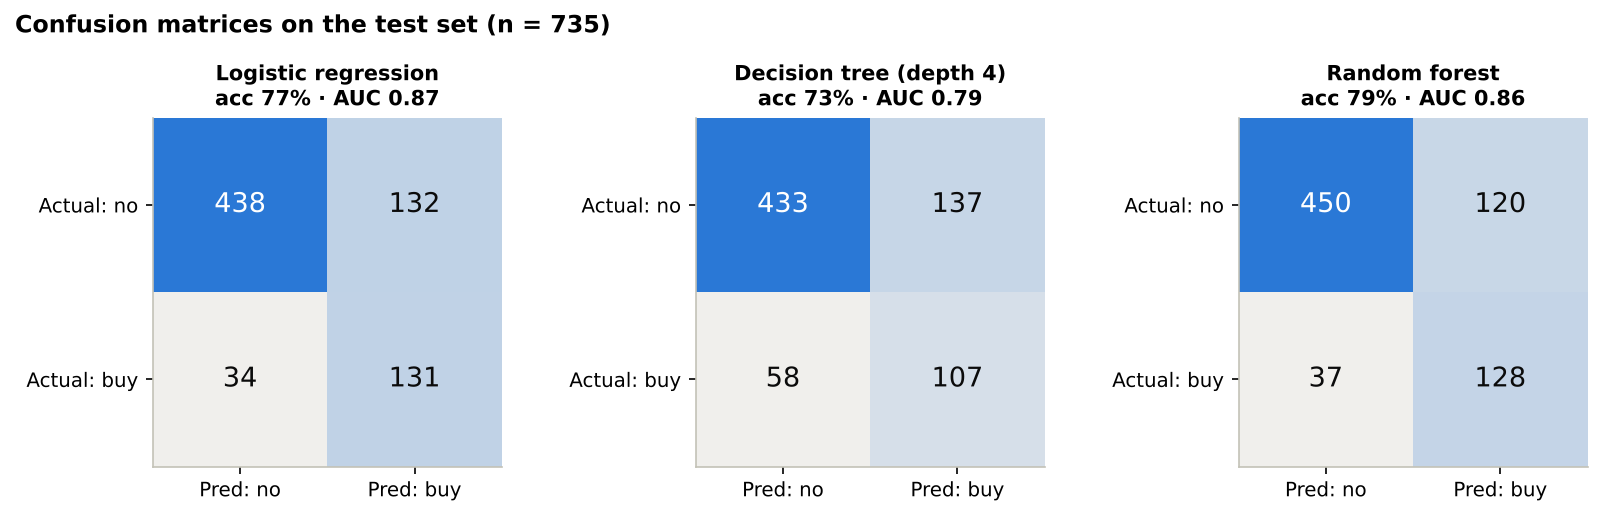

In [3]:
cls = M.classification(s)
res = cls["results"]
display(res.drop(columns="cm").round(3))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, r in zip(axes, res.itertuples()):
    cm = r.cm
    ax.imshow(cm, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("b", ["#f0efec", C.POS]))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=13, color="white" if cm[i, j] > cm.max() * .5 else C.INK)
    ax.set_xticks([0, 1], ["Pred: no", "Pred: buy"]); ax.set_yticks([0, 1], ["Actual: no", "Actual: buy"])
    ax.set_title(f"{r.model}\nacc {r.accuracy:.0%} · AUC {r.auc:.2f}", fontsize=10)
fig.suptitle("Confusion matrices on the test set (n = %d)" % cls["n_test"], x=.02, ha="left", fontweight="bold")
save(fig, "cls_confusion")

In [4]:
best = cls["best"]
display(Markdown(f"""**Reading the result.** The best model is **{best.model}** (test AUC {best.auc:.2f}, 5-fold cross-validated AUC
{best.cv_auc:.2f}). It catches {best.recall:.0%} of real buyers; {best.precision:.0%} of the people it flags actually buy, against a
base rate of {cls['base_rate']:.0%} – so targeting its list is about {best.precision / cls['base_rate']:.1f}x better than random.
The **decision tree is the weakest** (AUC {res.set_index('model').auc['Decision tree (depth 4)']:.2f}): a shallow tree cuts each factor into a
few steps, while purchase intent rises smoothly with each factor. Logistic regression also explains *why*, through its odds ratios below."""))

**Reading the result.** The best model is **Logistic regression** (test AUC 0.87, 5-fold cross-validated AUC
0.86). It catches 79% of real buyers; 50% of the people it flags actually buy, against a
base rate of 22% – so targeting its list is about 2.2x better than random.
The **decision tree is the weakest** (AUC 0.79): a shallow tree cuts each factor into a
few steps, while purchase intent rises smoothly with each factor. Logistic regression also explains *why*, through its odds ratios below.

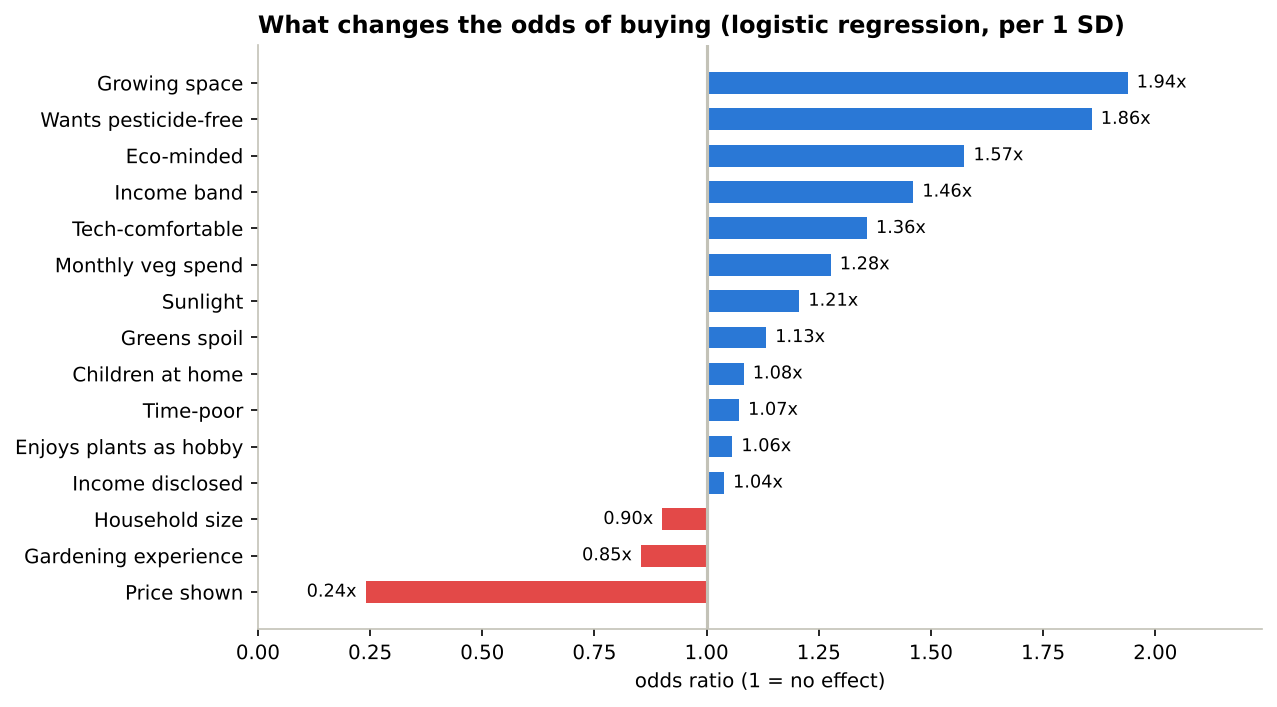

Odds ratio above 1 = raises the chance of buying; below 1 = lowers it. Growing space, health attitude and eco attitude raise the odds most; a higher price shown lowers them most. These match the diagnostic correlations in Step 3, now with every other factor held constant.

In [5]:
o = cls["odds"]
fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.barh(o.factor, o.odds_ratio_per_sd - 1, left=1, color=[C.POS if v >= 1 else C.NEG for v in o.odds_ratio_per_sd], height=.6)
ax.axvline(1, color=C.AXIS); ax.set_xlim(0, o.odds_ratio_per_sd.max() + .3)
for y, v in enumerate(o.odds_ratio_per_sd):
    ax.text(v + (.02 if v >= 1 else -.02), y, f"{v:.2f}x", va="center", ha="left" if v >= 1 else "right", fontsize=8.5)
ax.set_title("What changes the odds of buying (logistic regression, per 1 SD)", loc="left"); ax.set_xlabel("odds ratio (1 = no effect)")
save(fig, "cls_odds")
display(Markdown("Odds ratio above 1 = raises the chance of buying; below 1 = lowers it. Growing space, health attitude and eco attitude "
                 "raise the odds most; a higher price shown lowers them most. These match the diagnostic correlations in Step 3, now "
                 "with every other factor held constant."))

### 1b. Lead scoring on the pilot – the classifier in the sales pipeline
The same idea applied to real pilot leads: predict which contacted lead will buy from channel, response time, price,
space, income, household size, demo type, rep and city. Leads are then ranked into ten equal groups (deciles) by score.

,model,accuracy,precision,recall,f1,auc
0,Logistic regression,0.758,0.396,0.782,0.526,0.835
1,Random forest,0.765,0.405,0.790,0.536,0.834


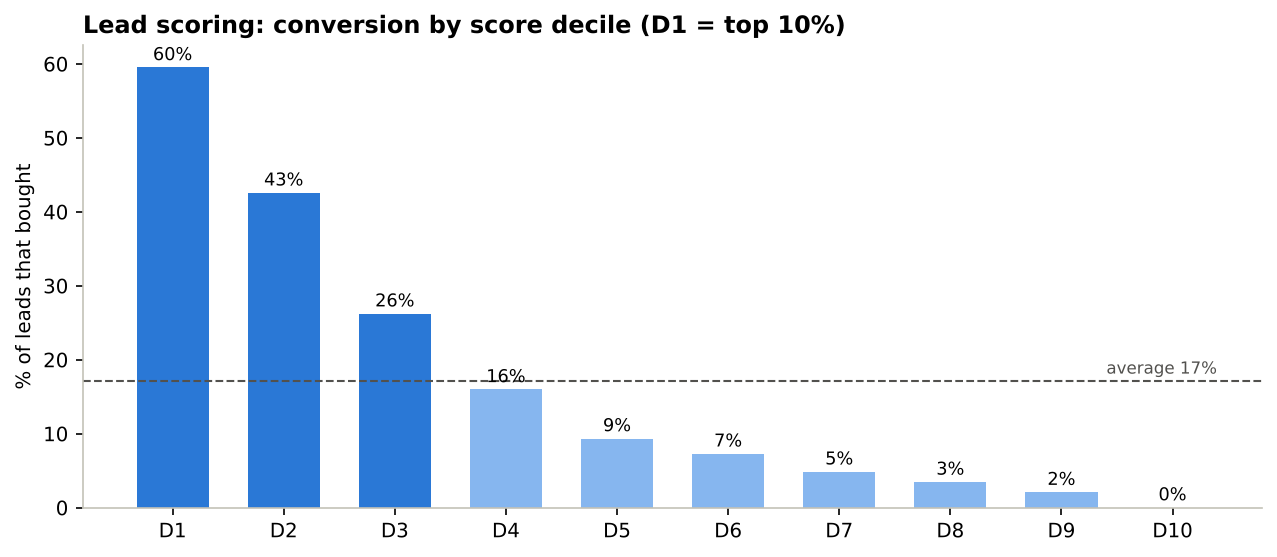

**Reading the result.** The top 30% of leads by score hold **75% of all buyers**; the top decile converts at
60% against an average of 17%. **Action:** call D1–D3 within 2 hours and offer in-person demos; send D7–D10
to automated WhatsApp nurturing instead of rep time.

In [6]:
ls = M.lead_scoring(p)
display(ls["results"].drop(columns="cm").round(3))
g = ls["gains"]
fig, ax = plt.subplots(figsize=(8.6, 3.8))
ax.bar(g.decile, g.conversion * 100, color=[C.POS] * 3 + ["#86b6ef"] * 7, width=.65)
for x, v in zip(g.decile, g.conversion):
    ax.text(x, v * 100 + 1, f"{v:.0%}", ha="center", fontsize=8.5)
ax.axhline(ls["base_rate"] * 100, color=C.INK2, ls="--", lw=1); ax.text(10.4, ls["base_rate"] * 100 + 1, f"average {ls['base_rate']:.0%}", ha="right", fontsize=8, color=C.INK2)
ax.set_xticks(g.decile, [f"D{d}" for d in g.decile]); ax.set_ylabel("% of leads that bought")
ax.set_title("Lead scoring: conversion by score decile (D1 = top 10%)", loc="left")
save(fig, "lead_gains")
display(Markdown(f"""**Reading the result.** The top 30% of leads by score hold **{g.cum_share_of_buyers.iloc[2]:.0%} of all buyers**; the top decile converts at
{g.conversion.iloc[0]:.0%} against an average of {ls['base_rate']:.0%}. **Action:** call D1–D3 within 2 hours and offer in-person demos; send D7–D10
to automated WhatsApp nurturing instead of rep time."""))

## 2. Clustering – customer segments (k-means)
**Why:** to find natural customer groups, rank them by conversion probability (high / medium / low), and design a
different offer for each. Inputs are standardised (z-scores) so rupees do not outweigh 1–5 scales.
**Choosing k:** the elbow (where extra clusters stop reducing spread much) and the silhouette score (how well separated
clusters are, −1 to 1).

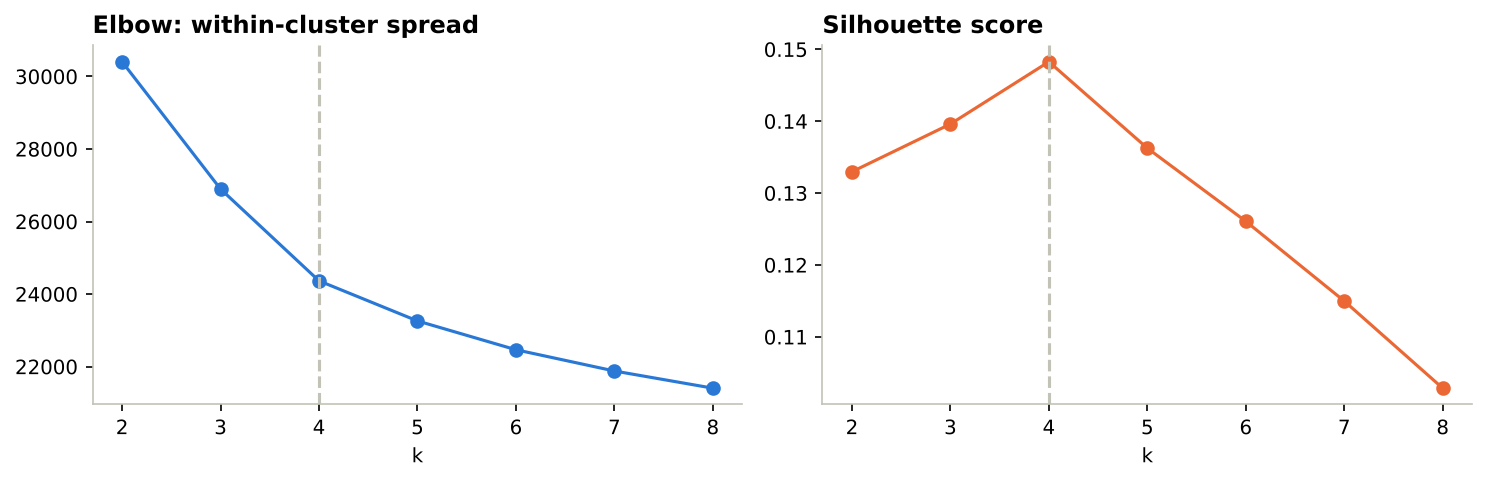

k = 4 has the **highest silhouette (0.148)** and sits at the bend of the elbow. A silhouette this low is
normal for attitude survey data – people do not fall into sharply separated groups – so segments are best read as *tendencies*,
not hard boxes. This is the main limitation of clustering here.

In [7]:
cl = M.clustering(s)
sc = cl["scan"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.3))
a1.plot(sc.k, sc.inertia, "o-", color=C.POS); a1.set_title("Elbow: within-cluster spread", loc="left"); a1.set_xlabel("k")
a2.plot(sc.k, sc.silhouette, "o-", color=C.SERIES[1]); a2.set_title("Silhouette score", loc="left"); a2.set_xlabel("k")
for a in (a1, a2):
    a.axvline(cl["k"], color=C.AXIS, ls="--")
save(fig, "clu_choose_k")
display(Markdown(f"""k = {cl['k']} has the **highest silhouette ({cl['silhouette']:.3f})** and sits at the bend of the elbow. A silhouette this low is
normal for attitude survey data – people do not fall into sharply separated groups – so segments are best read as *tendencies*,
not hard boxes. This is the main limitation of clustering here."""))

,name,probability_tier,size,share,would_buy,would_subscribe,median_wtp,income,space,health,eco,tech,time_poor,hobby,metro
0,Health-first families,High,907,0.31,0.32,0.51,5500.0,3.29,1.44,4.25,3.54,3.59,4.11,3.07,0.73
1,Hobby terrace gardeners,Medium,589,0.20,0.30,0.18,5000.0,2.68,2.66,3.84,3.84,2.74,2.60,4.28,0.37
2,Busy tech-savvy professionals,Medium,674,0.23,0.24,0.47,5000.0,3.07,0.99,3.69,4.25,4.33,3.86,3.34,0.81
3,Budget-conscious households,Low,770,0.26,0.04,0.06,2000.0,1.69,0.96,3.04,2.96,2.84,3.05,2.97,0.51


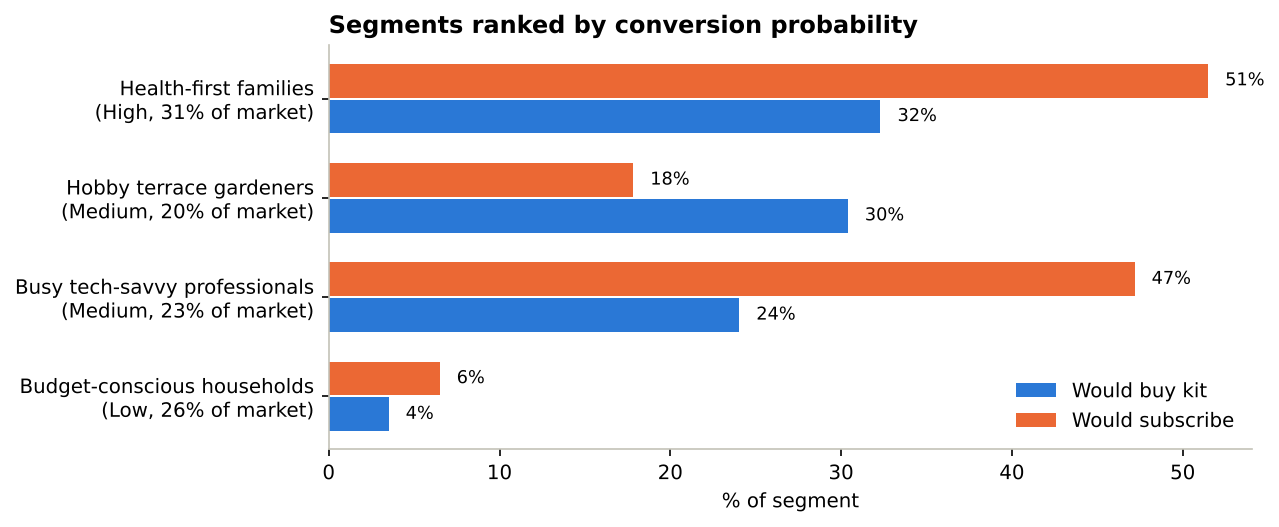

In [8]:
pr = cl["profile"]
show = pr[["name", "probability_tier", "size", "share", "would_buy", "would_subscribe", "median_wtp", "income", "space", "health", "eco", "tech",
           "time_poor", "hobby", "metro"]].copy()
display(show.round(2))
fig, ax = plt.subplots(figsize=(8.6, 3.6))
y = np.arange(len(pr))
ax.barh(y + .18, pr.would_buy * 100, height=.34, color=C.POS, label="Would buy kit")
ax.barh(y - .18, pr.would_subscribe * 100, height=.34, color=C.SERIES[1], label="Would subscribe")
for yy, a_, b_ in zip(y, pr.would_buy, pr.would_subscribe):
    ax.text(a_ * 100 + 1, yy + .18, f"{a_:.0%}", va="center", fontsize=8.5); ax.text(b_ * 100 + 1, yy - .18, f"{b_:.0%}", va="center", fontsize=8.5)
ax.set_yticks(y, [f"{n}\n({t}, {sh:.0%} of market)" for n, t, sh in zip(pr.name, pr.probability_tier, pr.share)]); ax.invert_yaxis()
ax.legend(frameon=False, loc="lower right"); ax.set_xlabel("% of segment")
ax.set_title("Segments ranked by conversion probability", loc="left")
save(fig, "clu_segments")

In [9]:
top = pr.iloc[0]; low = pr.iloc[-1]
subs_rank = pr.sort_values("would_subscribe", ascending=False)
sub_best = subs_rank.iloc[1] if subs_rank.iloc[0]['name'] == pr.iloc[0]['name'] else subs_rank.iloc[0]
display(Markdown(f"""**Reading the result.**
* **{top['name']}** (high probability, {top.share:.0%} of the market): {top.would_buy:.0%} would buy, median max price ₹{top.median_wtp:,.0f}. Launch target.
* **{sub_best['name']}** ({sub_best.probability_tier.lower()}, {sub_best.share:.0%}): buy intent {sub_best.would_buy:.0%} but subscription intent {sub_best.would_subscribe:.0%}, close to the top
  segment – market the refill to them on convenience ("never think about seeds again").
* **{pr.iloc[1]['name']}** ({pr.iloc[1].probability_tier.lower()}, {pr.iloc[1].share:.0%}): {pr.iloc[1].would_buy:.0%} would buy, but only {pr.iloc[1].would_subscribe:.0%} would
  subscribe – they buy the kit and grow their own seeds, so sell them the expansion tier, not the refill.
* **{low['name']}** (low, {low.share:.0%}): only {low.would_buy:.0%} would buy and median max price is ₹{low.median_wtp:,.0f} – exclude from paid
  marketing; serve later with a cheaper entry kit."""))

**Reading the result.**
* **Health-first families** (high probability, 31% of the market): 32% would buy, median max price ₹5,500. Launch target.
* **Busy tech-savvy professionals** (medium, 23%): buy intent 24% but subscription intent 47%, close to the top
  segment – market the refill to them on convenience ("never think about seeds again").
* **Hobby terrace gardeners** (medium, 20%): 30% would buy, but only 18% would
  subscribe – they buy the kit and grow their own seeds, so sell them the expansion tier, not the refill.
* **Budget-conscious households** (low, 26%): only 4% would buy and median max price is ₹2,000 – exclude from paid
  marketing; serve later with a cheaper entry kit.

## 3. Association rule mining – which features go together (Apriori)
**Why:** the product could ship with nine features. Association rules show bundles: *if a customer wants A (and B), how
likely do they also want C?* That decides which features must launch together so customers are not left wanting the
missing one. **Support** = share of all respondents with the bundle; **confidence** = P(C | A and B);
**lift** = confidence ÷ how common C is anyway (above 1 = a real association).

In [10]:
ar = M.association(s)
display(Markdown(f"{ar['n_itemsets']} frequent itemsets (support ≥ 6%) and {len(ar['rules'])} rules with confidence ≥ 45% and lift > 1.05. "
                 "Feature-to-feature rules:"))
display(ar["feature_rules"].round(3))
display(Markdown("Top rules including crops:")); display(ar["rules"].head(10).round(3))

154 frequent itemsets (support ≥ 6%) and 60 rules with confidence ≥ 45% and lift > 1.05. Feature-to-feature rules:

,if,then,support,confidence,lift
0,Installation visits,Self-watering,0.063,0.492,1.225
1,Refill subscription + Vertical / stackable,Self-watering,0.075,0.485,1.206
2,Grow light,Vertical / stackable,0.120,0.691,1.179
3,Refill subscription,Self-watering,0.121,0.471,1.174
4,Hydroponic,Self-watering,0.151,0.457,1.137
5,Hydroponic + Vertical / stackable,Self-watering,0.091,0.455,1.132
6,Refill subscription + Self-watering,Vertical / stackable,0.075,0.620,1.057


Top rules including crops:

,if,then,support,confidence,lift
0,Leafy greens + Soil / cocopeat,Tomatoes & chillies,0.069,0.478,1.466
1,Smart sensor + app,Hydroponic,0.085,0.480,1.448
2,Soil / cocopeat,Tomatoes & chillies,0.117,0.470,1.442
3,Herbs + Soil / cocopeat,Tomatoes & chillies,0.077,0.464,1.425
4,Leafy greens + Microgreens + Vertical / stackable,Organic seeds,0.061,0.525,1.412
5,Herbs + Leafy greens + Microgreens,Organic seeds,0.062,0.500,1.345
6,Leafy greens + Microgreens,Organic seeds,0.093,0.494,1.328
7,Microgreens + Organic seeds + Vertical / stackable,Leafy greens,0.061,0.709,1.243
8,Herbs + Hydroponic + Leafy greens,Self-watering,0.064,0.496,1.235
9,Leafy greens + Refill subscription,Organic seeds,0.068,0.458,1.231


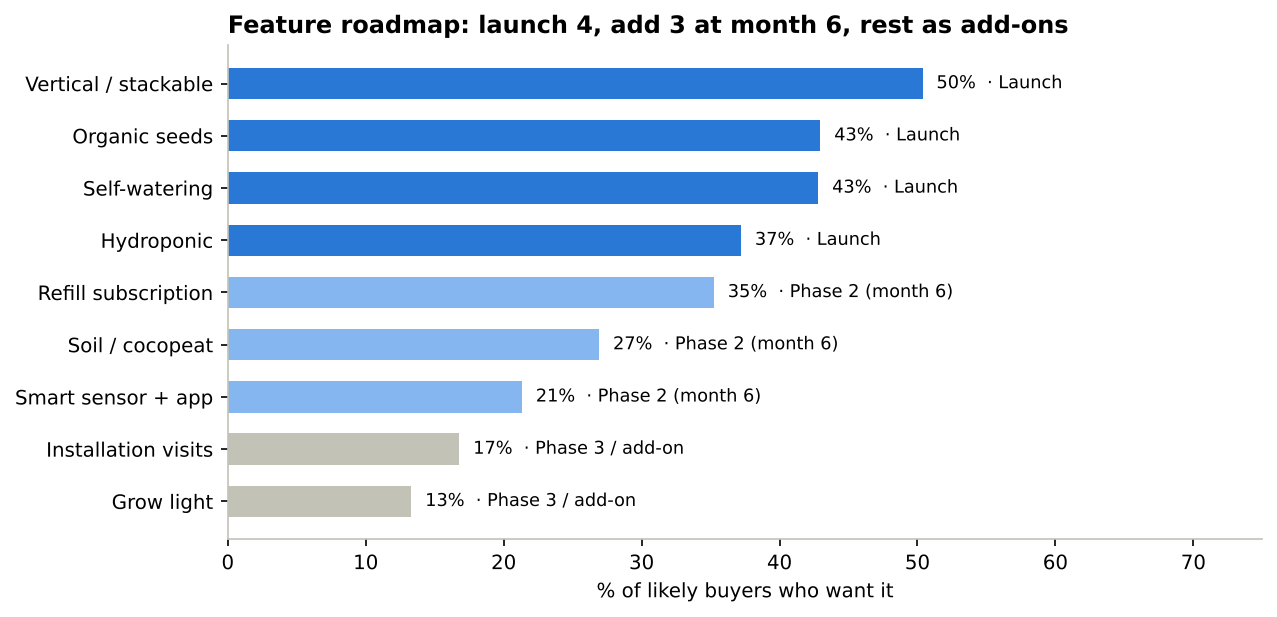

**Reading the result.** Lifts are modest (highest 1.47): most features are wanted fairly independently, so
association rules are the **weakest of the four techniques on this data** – useful for bundling, not for big decisions. The rules that do
exist point the same way: customers who want hydroponics, installation or the refill subscription also want **self-watering**, and grow-light
buyers want a **vertical** system (69% confidence). So the launch kit = **vertical +
self-watering + organic seeds + hydroponic pods**; the refill subscription, soil option and smart sensor follow at month 6.

In [11]:
la = ar["launch"]
fig, ax = plt.subplots(figsize=(8.6, 4.2))
col = {"Launch": C.POS, "Phase 2 (month 6)": "#86b6ef", "Phase 3 / add-on": C.AXIS}
ax.barh(la.feature, la.wanted_by_likely_buyers * 100, color=[col[x] for x in la.phase], height=.6)
for yy, v, ph in zip(range(len(la)), la.wanted_by_likely_buyers, la.phase):
    ax.text(v * 100 + 1, yy, f"{v:.0%}  · {ph}", va="center", fontsize=8.5)
ax.invert_yaxis(); ax.set_xlim(0, 75); ax.set_xlabel("% of likely buyers who want it")
ax.set_title("Feature roadmap: launch 4, add 3 at month 6, rest as add-ons", loc="left")
save(fig, "arm_roadmap")
r0 = ar["feature_rules"].iloc[0] if len(ar["feature_rules"]) else None
display(Markdown(f"""**Reading the result.** Lifts are modest (highest {ar['rules'].lift.max():.2f}): most features are wanted fairly independently, so
association rules are the **weakest of the four techniques on this data** – useful for bundling, not for big decisions. The rules that do
exist point the same way: customers who want hydroponics, installation or the refill subscription also want **self-watering**, and grow-light
buyers want a **vertical** system ({ar['feature_rules'].set_index('if').confidence.get('Grow light', float('nan')):.0%} confidence). So the launch kit = **vertical +
self-watering + organic seeds + hydroponic pods**; the refill subscription, soil option and smart sensor follow at month 6."""))

## 4. Regression – how much will customers pay?
**Why:** classification says *whether* someone buys; regression says *how much* they would pay (Q16a, ₹), which sets
price tiers per segment. Ordinary least squares gives interpretable rupee effects; a random forest checks whether a
non-linear model does better.

In [12]:
rg = M.regression(s)
display(rg["perf"].round(3))
display(rg["coef"].round(3))

,model,r2_test,mae,r2_train
0,Linear regression (OLS),0.737,849.746,0.716
1,Random forest regressor,0.692,918.016,0.764


,factor,rupees_per_unit,p_value,significant
10,Household size,-63.392,0.021,True
9,Gardening experience,-36.329,0.186,False
3,Monthly veg spend,0.192,0.000,True
8,Enjoys plants as hobby,87.836,0.001,True
11,Children at home,110.877,0.029,True
7,Time-poor,237.539,0.000,True
2,Sunlight,264.000,0.000,True
6,Tech-comfortable,334.166,0.000,True
5,Eco-minded,380.204,0.000,True
4,Wants pesticide-free,435.502,0.000,True


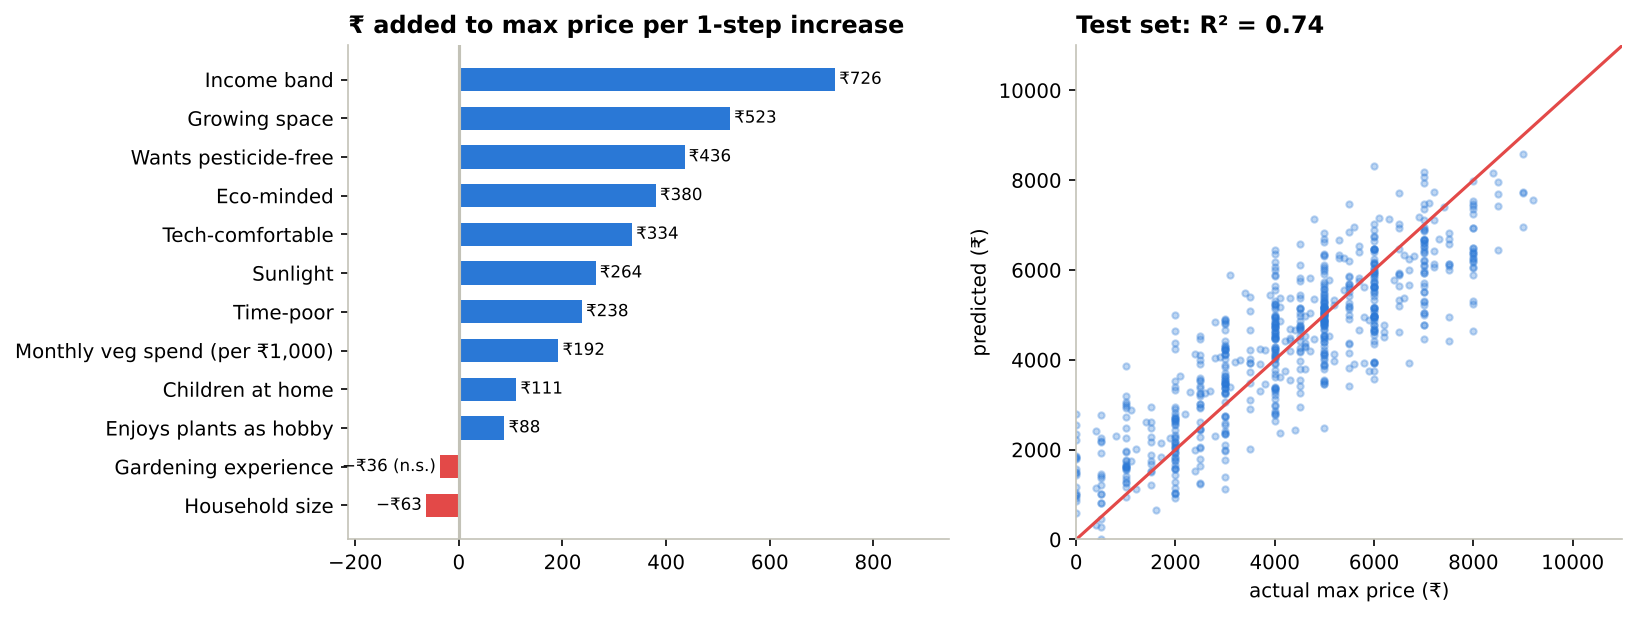

**Reading the result.** The linear model explains **74% of the variation** in willingness to pay on unseen data
(average error ₹850). The random forest does *worse* on the test set (R² 0.69) although better on training data
(0.76) – it overfits, and the simpler model wins. Each income band adds ₹726, each space
step ₹523, and each point of health attitude ₹436.
**Action:** a ₹4,999 standard kit for the high-probability segments, a premium ₹6,999 bundle (expansion tier + sensor) for large-balcony and
terrace homes earning ₹2 lakh+ a month, and a ₹2,999 starter for budget households later.

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
cf = rg["coef"].copy()
vs = cf.factor == "Monthly veg spend"; cf.loc[vs, "rupees_per_unit"] *= 1000; cf.loc[vs, "factor"] = "Monthly veg spend (per ₹1,000)"
cf = cf.sort_values("rupees_per_unit")
a1.barh(cf.factor, cf.rupees_per_unit, color=[C.POS if v >= 0 else C.NEG for v in cf.rupees_per_unit], alpha=1, height=.6)
a1.axvline(0, color=C.AXIS); a1.set_title("₹ added to max price per 1-step increase", loc="left")
for yy, (v, sig) in enumerate(zip(cf.rupees_per_unit, cf.significant)):
    a1.text(v + (8 if v >= 0 else -8), yy, ("−₹" if v < 0 else "₹") + f"{abs(v):,.0f}" + ("" if sig else " (n.s.)"), va="center", ha="left" if v >= 0 else "right", fontsize=8)
a1.set_xlim(cf.rupees_per_unit.min() - 150, cf.rupees_per_unit.max() + 220)
av = rg["actual_vs_pred"]
a2.scatter(av.actual, av.predicted, s=9, alpha=.3, color=C.POS); lim = [0, 11000]
a2.plot(lim, lim, color=C.NEG, lw=1.5); a2.set_xlim(lim); a2.set_ylim(lim)
a2.set_xlabel("actual max price (₹)"); a2.set_ylabel("predicted (₹)")
a2.set_title(f"Test set: R² = {rg['perf'].r2_test.iloc[0]:.2f}", loc="left")
save(fig, "reg_wtp")
ols = rg["perf"].iloc[0]; rf = rg["perf"].iloc[1]
display(Markdown(f"""**Reading the result.** The linear model explains **{ols.r2_test:.0%} of the variation** in willingness to pay on unseen data
(average error ₹{ols.mae:,.0f}). The random forest does *worse* on the test set (R² {rf.r2_test:.2f}) although better on training data
({rf.r2_train:.2f}) – it overfits, and the simpler model wins. Each income band adds ₹{cf.set_index('factor').rupees_per_unit['Income band']:,.0f}, each space
step ₹{cf.set_index('factor').rupees_per_unit['Growing space']:,.0f}, and each point of health attitude ₹{cf.set_index('factor').rupees_per_unit['Wants pesticide-free']:,.0f}.
**Action:** a ₹4,999 standard kit for the high-probability segments, a premium ₹6,999 bundle (expansion tier + sensor) for large-balcony and
terrace homes earning ₹2 lakh+ a month, and a ₹2,999 starter for budget households later."""))

## 5. Which algorithm worked best – and which failed?

In [14]:
cmp = pd.DataFrame([
    ("Classification – logistic regression", "Test AUC / recall", f"{res.auc.iloc[0]:.2f} / {res.recall.iloc[0]:.0%}", "Best: accurate and explainable"),
    ("Classification – random forest", "Test AUC / recall", f"{res.auc.iloc[2]:.2f} / {res.recall.iloc[2]:.0%}", "Equal accuracy, harder to explain"),
    ("Classification – decision tree", "Test AUC / recall", f"{res.auc.iloc[1]:.2f} / {res.recall.iloc[1]:.0%}", "Weakest classifier: too coarse"),
    ("Lead scoring (pilot)", "Test AUC; top-30% buyers", f"{ls['results'].auc.iloc[0]:.2f}; {g.cum_share_of_buyers.iloc[2]:.0%}", "Strong: directly usable by sales"),
    ("Regression – OLS", "Test R² / MAE", f"{ols.r2_test:.2f} / ₹{ols.mae:,.0f}", "Strong: sets price tiers"),
    ("Regression – random forest", "Test R² / MAE", f"{rf.r2_test:.2f} / ₹{rf.mae:,.0f}", "Overfits; simpler model wins"),
    ("Clustering – k-means", "Silhouette", f"{cl['silhouette']:.3f}", "Useful segments, weak separation"),
    ("Association rules", "Best lift", f"{ar['rules'].lift.max():.2f}", "Weakest: features mostly independent"),
], columns=["Algorithm", "Metric", "Result", "Verdict"])
cmp

,Algorithm,Metric,Result,Verdict
0,Classification – logistic regression,Test AUC / recall,0.87 / 79%,Best: accurate and explainable
1,Classification – random forest,Test AUC / recall,0.86 / 78%,"Equal accuracy, harder to explain"
2,Classification – decision tree,Test AUC / recall,0.79 / 65%,Weakest classifier: too coarse
3,Lead scoring (pilot),Test AUC; top-30% buyers,0.83; 75%,Strong: directly usable by sales
4,Regression – OLS,Test R² / MAE,0.74 / ₹850,Strong: sets price tiers
5,Regression – random forest,Test R² / MAE,0.69 / ₹918,Overfits; simpler model wins
6,Clustering – k-means,Silhouette,0.148,"Useful segments, weak separation"
7,Association rules,Best lift,1.47,Weakest: features mostly independent


## 6. Prescriptive – break-even and payback
**Why:** a business can have demand and still never make money. This model runs 48 months forward with the unit
economics measured in the pilot and compares two strategies.

**Assumptions (stated, not data):** ₹25 lakh upfront (tooling, first stock, launch); fixed costs ₹3.5 lakh/month in
year 1 and ₹6 lakh/month from year 2 (team, warehouse, software); 80 new buyers in month 1 growing 6% a month (cap 600);
kit contribution ₹1,708 per buyer and ₹141 per refill box, both from the pilot.

The strategy changes three inputs, each taken from the pilot itself: CAC of the two best channels only, churn of
subscribers whose first harvest came within 35 days, and refill attach +10 points from targeting the high-subscription segment.

,cac,kit_margin,attach,churn,buyers_m1,breakeven_month,payback_month,lowest_cash_position_inr
Pilot as-is,1712.801,1708.092,0.428,0.094,80.0,NaN,NaN,-2.095564e+07
Data-driven strategy,709.563,1708.092,0.528,0.061,80.0,28.0,48.0,-7.898787e+06


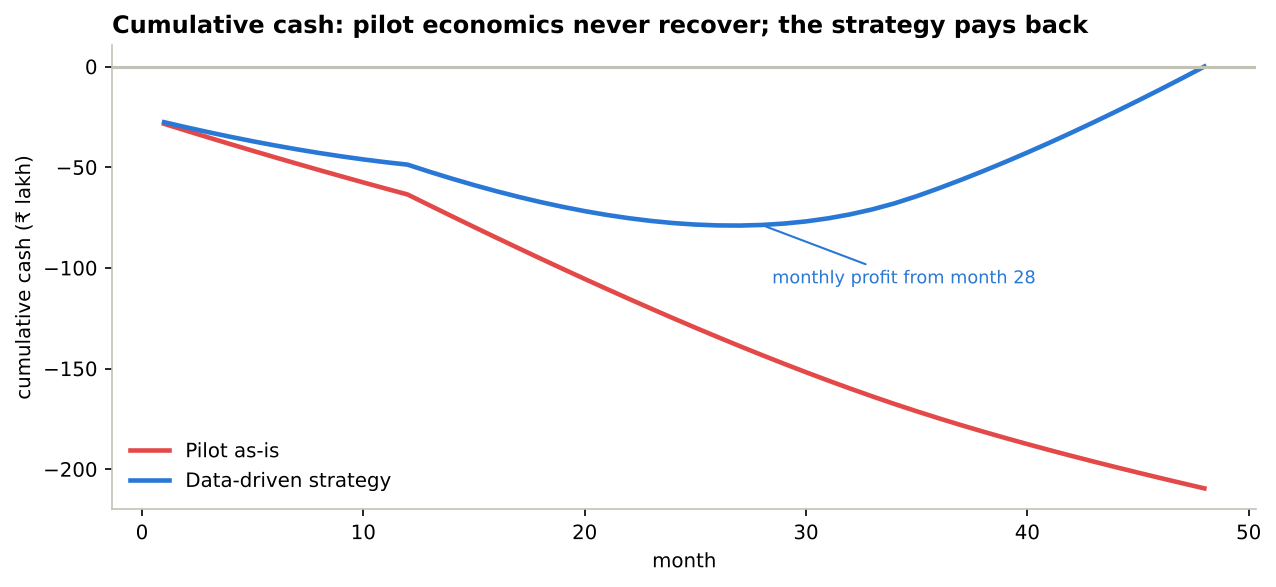

In [15]:
pres = M.prescriptive(s, p)
inp = pd.DataFrame({k: v["inputs"] for k, v in pres.items()}).T
inp["breakeven_month"] = [v["breakeven"] for v in pres.values()]
inp["payback_month"] = [v["payback"] for v in pres.values()]
inp["lowest_cash_position_inr"] = [v["min_cash"] for v in pres.values()]
display(inp.round(3))
fig, ax = plt.subplots(figsize=(8.6, 4))
for (name, v), colr in zip(pres.items(), [C.NEG, C.POS]):
    t = v["table"]; ax.plot(t.month, t.cumulative / 1e5, color=colr, lw=2.2, label=name)
    if v["breakeven"]:
        ax.annotate(f"monthly profit from month {v['breakeven']}", (v["breakeven"], t.cumulative.iloc[v['breakeven'] - 1] / 1e5),
                    xytext=(5, -28), textcoords="offset points", fontsize=8.5, color=colr, arrowprops=dict(arrowstyle="-", color=colr))
ax.axhline(0, color=C.AXIS); ax.set_xlabel("month"); ax.set_ylabel("cumulative cash (₹ lakh)")
ax.legend(frameon=False, loc="lower left"); ax.set_title("Cumulative cash: pilot economics never recover; the strategy pays back", loc="left")
save(fig, "breakeven")

In [16]:
dd = pres["Data-driven strategy"]; pa = pres["Pilot as-is"]
display(Markdown(f"""**Reading the result.** With the pilot's economics (CAC ₹{pa['inputs']['cac']:,.0f} ≈ kit margin, {pa['inputs']['churn']:.1%} churn)
the business **never reaches monthly profit in 48 months**: every new customer costs as much to win as the kit earns, and refill income
leaks away through churn. With the strategy the algorithms point to – acquire through society demos and referrals (CAC
₹{dd['inputs']['cac']:,.0f}), get every first harvest inside 35 days (churn {dd['inputs']['churn']:.1%}), and push the refill to the high-subscription
segment (attach {dd['inputs']['attach']:.0%}) – it reaches **monthly profit in month {dd['breakeven']}** and **pays back all cash in month {dd['payback']}**.
Peak funding needed is about **₹{-dd['min_cash'] / 1e5:,.0f} lakh**.

**Verdict: sustainable only with the data-driven strategy.** The same product with the pilot's channel mix and onboarding is not."""))

**Reading the result.** With the pilot's economics (CAC ₹1,713 ≈ kit margin, 9.4% churn)
the business **never reaches monthly profit in 48 months**: every new customer costs as much to win as the kit earns, and refill income
leaks away through churn. With the strategy the algorithms point to – acquire through society demos and referrals (CAC
₹710), get every first harvest inside 35 days (churn 6.1%), and push the refill to the high-subscription
segment (attach 53%) – it reaches **monthly profit in month 28** and **pays back all cash in month 48**.
Peak funding needed is about **₹79 lakh**.

**Verdict: sustainable only with the data-driven strategy.** The same product with the pilot's channel mix and onboarding is not.

## 7. The prescriptive plan – what to do, for whom, in what order
| Decision | Recommendation | Evidence (algorithm) |
|---|---|---|
| Whom to target | Health-first families first (kit + refill); hobby terrace gardeners for kit + expansion tier; busy tech-savvy professionals for the refill; skip budget households | Clustering |
| Which leads to work | Score every lead; D1–D3 get a call within 2 h and an in-person demo; D7–D10 get automated nurturing | Classification (lead scoring) |
| What to launch | Vertical + self-watering + organic seeds + hydroponic pods; refill, soil option, sensor at month 6 | Association rules |
| What price | ₹4,999 standard; ₹6,999 premium bundle for large-balcony/terrace homes earning ₹2 lakh+; ₹2,999 starter later | Regression + A/B test |
| Which channels | Society demo days and ₹300 referral reward; pause Instagram and Google search | LTV:CAC (Step 3) |
| How to retain | First harvest ≤ 35 days, week-1 onboarding call | Pilot diagnostics (Step 3) |
| When it pays | Monthly profit from month 28, payback month 48, ~₹79 lakh peak funding | Break-even model |